# Unconstrained parameter experiments: frozen vs. trained P

The other experiments freeze the top-left $d \times d$ block of every value matrix to zero,
so $P = \begin{bmatrix} 0 & 0 \\ 0 & 1 \end{bmatrix}$ (Gatmiry et al., 2024) and only $Q$ (= $A$) is trained.
Here the same layered and looped transformers are also trained with that block left free,
and both settings are drawn on the same axes.

- **Solid lines**: P frozen (top-left block fixed at 0)
- **Dashed lines**: P trained (unconstrained)

In [1]:
import os
import warnings

import numpy as np
import torch
from matplotlib import pyplot as plt

from experiments_helper import (
    run_experiment_suite,
    compute_loss_dict,
    compute_dist_dict,
    plot_parameter_matrices,
)

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

log_dir = 'log'
fig_dir = os.path.join('figures', 'unconstrained_parameters')
os.makedirs(log_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

In [2]:
# Problem parameters (defined in experiments_helper.py; edit them there so the
# helper functions see the same values)

from experiments_helper import (
    device, lr, clip_r, alg, normal_data_mode, N, d, n_head, B, var,
    max_iters, hist_stride, stride, TEST_SEED,
)

print(f'Running on device: {device}.')

Running on device: cuda.


## Train both settings

Run keys in `hist_dict` don't record `freeze_p`, so each setting is trained into its own
history file. Set `RETRAIN = False` to reload histories saved by an earlier run.

In [4]:
seeds = [0]
n_layers_loops = [5, 10]
model_types = ['looped']

RETRAIN = True

P_SETTINGS = {
    # label: freeze_p
    'P frozen': True,
    'P trained': False,
}
P_LINESTYLES = {'P frozen': '-', 'P trained': '--'}


def history_path(freeze_p):
    tag = 'frozen' if freeze_p else 'unfrozen'
    return os.path.join(log_dir, f'unconstrained_parameters_P-{tag}_N{N}_d{d}.pth')


hist_dicts = {}
for setting, freeze_p in P_SETTINGS.items():
    path = history_path(freeze_p)
    if not RETRAIN and os.path.exists(path):
        print(f'Loading {setting} histories from {path}')
        hist_dicts[setting] = torch.load(path, weights_only=False)['hist_dict']
    else:
        print(f'===== Training: {setting} =====')
        hist_dicts[setting] = run_experiment_suite(
            seeds, n_layers_loops, model_types, path, freeze_p=freeze_p,
        )

===== Training: P frozen =====
Run 1/2: seed=0, count=5, type=looped, N=10, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear, freeze_p=True
iter 0 | Loss: 17.92928123474121 | time: 0.009521007537841797 | gradnorm: 165.81643676757812
iter 1 | Loss: 14.664645195007324 | time: 0.011237382888793945 | gradnorm: 124.70455169677734
iter 2 | Loss: 13.553898811340332 | time: 0.01507425308227539 | gradnorm: 110.50276184082031
iter 3 | Loss: 12.8226900100708 | time: 0.014282703399658203 | gradnorm: 102.61194610595703
iter 4 | Loss: 13.936625480651855 | time: 0.01411890983581543 | gradnorm: 120.3150405883789
iter 100 | Loss: 3.549886703491211 | time: 0.013907432556152344 | gradnorm: 21.042280197143555
iter 200 | Loss: 1.917795181274414 | time: 0.013909578323364258 | gradnorm: 7.704891681671143
iter 300 | Loss: 1.1881790161132812 | time: 0.013904809951782227 | gradnorm: 3.0408756732940674
iter 400 | Loss: 0.8246211409568787 | time: 

In [5]:
loss_dicts = {
    setting: compute_loss_dict(hist_dict, test_seed=TEST_SEED)
    for setting, hist_dict in hist_dicts.items()
}

iterations = np.arange(0, max_iters, stride)

(0, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=5, type=looped, N=10, train data=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear
(0, 10, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=10, type=looped, N=10, train data=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear
(0, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=5, type=looped, N=10, train data=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear
(0, 10, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=10, type=loop

## Plotting helpers

Each curve is the mean over seeds, with a ±1 std band. Colour encodes the layer/loop count,
line style encodes whether P was frozen.

In [6]:
COUNT_COLORS = dict(zip(n_layers_loops, ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']))
MODEL_LABELS = {'layered': 'baseline (layered)', 'looped': 'looping (shared weights)'}


def seed_mean_std(curves):
    """Mean and std over seeds (dim 0), ignoring non-finite values."""
    curves = np.asarray(curves, dtype=float)
    curves = np.where(np.isfinite(curves), curves, np.nan)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=RuntimeWarning)
        mean = np.nanmean(curves, axis=0)
        std = np.nanstd(curves, axis=0)
    n_valid = np.isfinite(curves).sum(axis=0)
    std = np.where(n_valid > 1, std, np.nan)
    return mean, std


def run_keys(result_dict, count, model_type):
    return [key for key in result_dict
            if key[0] in seeds and key[1] == count and key[2] == model_type]


def overlay_plot(curve_fn, x, model_type, ylabel, title, filename, log_scale=False):
    """Draw frozen vs trained P for every count on a single axis.

    `curve_fn(setting, key)` returns the 1-D curve for one run.
    """
    fig, ax = plt.subplots(figsize=(9, 6))
    for count in n_layers_loops:
        for setting in P_SETTINGS:
            keys = run_keys(loss_dicts[setting], count, model_type)
            curves = [curve_fn(setting, key) for key in keys]
            curves = [c for c in curves if c is not None]
            if not curves:
                continue
            mean, std = seed_mean_std(curves)
            color = COUNT_COLORS[count]
            ax.plot(x, mean, color=color, linestyle=P_LINESTYLES[setting], lw=2.2,
                    label=f'count={count}, {setting}')
            ax.fill_between(x, mean - std, mean + std, color=color, alpha=0.10)

    ax.set_title(f'{title}: {MODEL_LABELS[model_type]}, N={N}, d={d}')
    ax.set_xlabel('Iteration', fontsize=14)
    ax.set_ylabel(ylabel, fontsize=14)
    ax.tick_params(axis='both', which='major', labelsize=11)
    if log_scale:
        ax.set_yscale('log')
    ax.grid(True, which='both', alpha=0.2)
    ax.legend(fontsize=9, ncol=2)
    fig.tight_layout()
    fig.savefig(os.path.join(fig_dir, filename), dpi=600, bbox_inches='tight')
    plt.show()

## Test loss: frozen vs. trained P

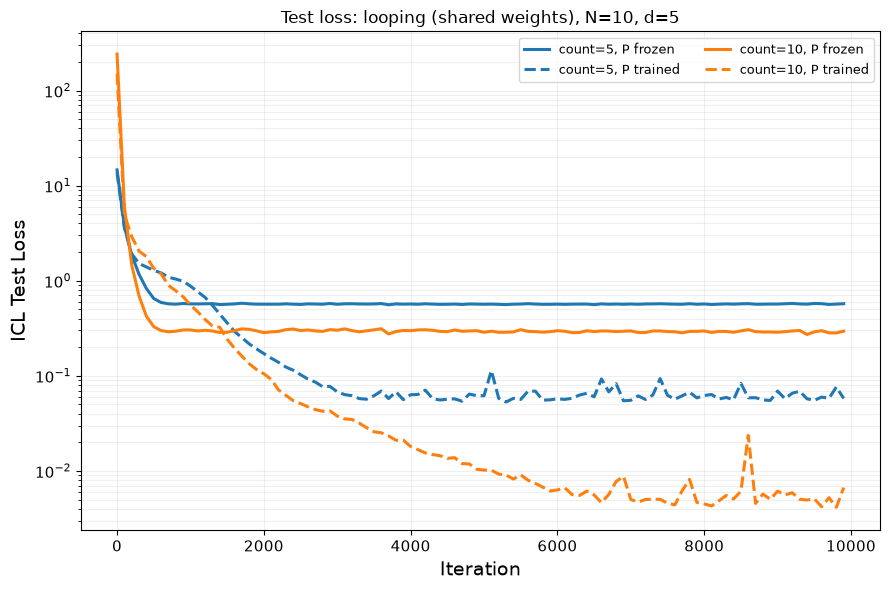

In [7]:
for model_type in model_types:
    overlay_plot(
        lambda setting, key: loss_dicts[setting][key].numpy(),
        iterations, model_type,
        ylabel='ICL Test Loss', title='Test loss',
        filename=f'test_loss_frozen_vs_trained_P_{model_type}_N{N}.pdf',
        log_scale=True,
    )

In [ ]:
# Final test loss (mean ± std over seeds) for each configuration
print(f'{"model":<10}{"count":>6}  {"P frozen":>22}  {"P trained":>22}')
for model_type in model_types:
    for count in n_layers_loops:
        row = f'{model_type:<10}{count:>6}'
        for setting in P_SETTINGS:
            keys = run_keys(loss_dicts[setting], count, model_type)
            finals = [loss_dicts[setting][key][-1].item() for key in keys]
            mean, std = seed_mean_std(np.array(finals)[:, None])
            row += f'  {mean[0]:>11.4g} ± {std[0]:<8.2g}'
        print(row)

## Distance of A (= Q) to a scaled identity

With P frozen, the paper predicts A converges toward a multiple of the identity
(for isotropic covariates). This checks whether that still holds when P is free to move.

In [ ]:
dist_dicts = {
    setting: compute_dist_dict(hist_dict, iterations, n_head, hist_stride=hist_stride)
    for setting, hist_dict in hist_dicts.items()
}

for model_type in model_types:
    overlay_plot(
        lambda setting, key: dist_dicts[setting][key][0, 1].numpy(),  # layer/loop 0, Q
        iterations, model_type,
        ylabel='Distance to identity', title='A (layer/loop 0) distance to identity',
        filename=f'dist_to_identity_A_frozen_vs_trained_P_{model_type}_N{N}.pdf',
    )

## How far does the trained P move from the frozen form?

Frobenius norm of P's learnable top-left $d \times d$ block, averaged over layers and heads.
For the frozen runs this is 0 throughout, so it serves as a reference line.

In [ ]:
def p_block_norm_curve(hist_dict, key):
    history = hist_dict[key]
    curve = np.full(len(iterations), np.nan)
    for i, iteration in enumerate(iterations):
        if iteration % hist_stride != 0:
            continue
        index = iteration // hist_stride
        if index >= len(history):
            break
        snapshot = history[index]
        if not torch.isfinite(snapshot).all():
            continue
        # snapshot: (layers, heads, P/Q, d, d)
        curve[i] = torch.linalg.matrix_norm(snapshot[:, :, 0], ord='fro').mean().item()
    return curve


for model_type in model_types:
    overlay_plot(
        lambda setting, key: p_block_norm_curve(hist_dicts[setting], key),
        iterations, model_type,
        ylabel=r'$\|P_{1:d,1:d}\|_F$ (mean over layers)',
        title='Norm of P top-left block',
        filename=f'P_block_norm_frozen_vs_trained_P_{model_type}_N{N}.pdf',
    )

## Learned matrices with P trained (seed 0)

Layer/loop-0 P and Q from the last checkpoint of the unconstrained runs.

In [ ]:
plot_parameter_matrices(hist_dicts['P trained'], seeds[0], n_layers_loops, model_types, n_head,
                        hist_stride=hist_stride, fig_dir=fig_dir)